# Few-shot prompting: what actually changes the answer?

**The idea.** A language model can pick up a task from a few worked examples placed *inside the prompt*. This is called **few-shot prompting**. We use **K** for the number of examples.

**The task.** Decide whether a movie-review sentence is *positive* or *negative* (the SST-2 dataset).

**The experiment.** Keep the task and the test sentences fixed. Change one thing at a time and watch the accuracy:

1. How many examples? (count)
2. In what order? (order)
3. Written in what style? (format)
4. What if some example labels are wrong? (labels)

**How it works.** We do not let the model write text. We show it the prompt and ask which is more likely as the next word: " positive" or " negative". No randomness, so the same prompt always gives the same answer.

**Before you run:** `Runtime > Change runtime type > T4 GPU`. The whole notebook takes about 10 minutes.

## 1. Setup

In [1]:
%pip install -q transformers datasets accelerate

In [2]:
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen2.5-1.5B"          # a small open model
device = "cuda" if torch.cuda.is_available() else "cpu"
print("running on:", device)

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, dtype=torch.float16 if device == "cuda" else torch.float32
).to(device).eval()
print("model loaded")

running on: cuda


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

model loaded


### 📋 Report · 1. Setup

**What happened.** The notebook installed the libraries and loaded **Qwen2.5-1.5B** (a base model, 1.5 billion parameters) on a **GPU** in 16-bit. The only warning (unauthenticated Hugging Face requests) is harmless: it just means slower downloads.

**The measuring idea.** No text is generated. For each test sentence, the model is asked which word is more likely next: ` positive` or ` negative`. This is deterministic, so the same prompt always gives the same answer, and any change in accuracy comes from the prompt.


## 2. The data

SST-2 has short movie-review sentences labelled 1 (positive) or 0 (negative).

- **Examples pool:** sentences from the training set. We pick our few-shot examples from here.
- **Test set:** 150 sentences (75 positive, 75 negative) from the validation set. **Every experiment uses these same 150**, so scores can be compared fairly.

In [3]:
from datasets import load_dataset

ds = None
for name, config in [("nyu-mll/glue", "sst2"), ("stanfordnlp/sst2", None)]:
    try:
        ds = load_dataset(name, config) if config else load_dataset(name)
        print("loaded", name)
        break
    except Exception as e:
        print("could not load", name, "-", type(e).__name__)
if ds is None:
    raise RuntimeError("Could not download SST-2. Re-run this cell, or check the internet connection.")

train = ds["train"].to_pandas()
valid = ds["validation"].to_pandas()

# keep medium-length sentences for the examples pool
train["sentence"] = train.sentence.str.strip()
train = train[train.sentence.str.split().str.len().between(8, 30)]
pos_pool = train[train.label == 1].sentence.tolist()
neg_pool = train[train.label == 0].sentence.tolist()

# the fixed test set: 75 positive + 75 negative
test = valid.groupby("label").sample(75, random_state=0).reset_index(drop=True)
test["sentence"] = test.sentence.str.strip()

print(len(pos_pool), "positive and", len(neg_pool), "negative example sentences available")
print(len(test), "test sentences")
test.head(3)

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

... (2 outputs left out)

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

loaded nyu-mll/glue
15261 positive and 14132 negative example sentences available
150 test sentences


,sentence,label,idx
0,( director ) o'fallon manages to put some love...,0,575
1,the most hopelessly monotonous film of the yea...,0,340
2,this movie is maddening .,0,113


### 📋 Report · 2. The data

**What happened.** The first source, `nyu-mll/glue`, loaded, so this run uses the **real SST-2** dataset.

| item | value |
|---|---|
| example pool | **15,261** positive and **14,132** negative training sentences (8-30 words long) |
| test set | **150** validation sentences, 75 positive and 75 negative, fixed with `random_state=0` |

**Things to notice**
- The test set is balanced, so **always guessing one label scores 50%**. That is the floor.
- Real SST-2 text is lowercase and pre-split ("o'fallon manages to put … , but … falls short ."), and often mixed: the first test sentence praises the pictures but calls the film a letdown, and is labelled negative. Some sentences are genuinely hard to call.
- Every experiment reuses these same 150 sentences, so the comparisons are fair.


## 3. Building prompts and scoring them

A prompt is just text: the examples, then the new review, then the start of the answer.

`make_prompt` builds it. `p_positive` asks the model how likely " positive" is compared with " negative" as the next word. `accuracy` runs this on all 150 test sentences and returns the share we get right.

In [4]:
# Four ways to write the SAME examples. Only the wording around them differs.
FORMATS = {
    "review/sentiment": "Review: {x}\nSentiment:{y}",
    "text/label":       "Text: {x}\nLabel:{y}",
    "question/answer":  "Q: Is this review positive or negative?\n{x}\nA:{y}",
    "arrow":            "{x} =>{y}",
}
LABELS = {1: " positive", 0: " negative"}


def make_prompt(demos, review, fmt="review/sentiment"):
    # demos is a list of (sentence, label) pairs
    template = FORMATS[fmt]
    shown = [template.format(x=s, y=LABELS[label]) for s, label in demos]
    question = template.format(x=review, y="")       # the answer is left blank
    return "\n\n".join(shown + [question])


pos_id = tok(" positive").input_ids[0]
neg_id = tok(" negative").input_ids[0]
assert pos_id != neg_id


@torch.no_grad()
def p_positive(prompt):
    # probability of " positive" versus " negative" as the next word
    inputs = tok(prompt, return_tensors="pt").to(device)
    logits = model(**inputs).logits[0, -1]
    two = torch.stack([logits[pos_id], logits[neg_id]]).float()
    return torch.softmax(two, dim=0)[0].item()


def accuracy(demos, fmt="review/sentiment"):
    correct = 0
    for review, label in zip(test.sentence, test.label):
        guess_positive = p_positive(make_prompt(demos, review, fmt)) > 0.5
        correct += int(guess_positive == bool(label))
    return correct / len(test)


def draw_demos(K, seed):
    # K random examples, about half positive and half negative, in random order
    rng = random.Random(seed)
    n_pos = K // 2 + (int(rng.random() < 0.5) if K % 2 else 0)
    demos = [(s, 1) for s in rng.sample(pos_pool, n_pos)]
    demos += [(s, 0) for s in rng.sample(neg_pool, K - n_pos)]
    rng.shuffle(demos)
    return demos


# Look at one real prompt with 2 examples
print(make_prompt(draw_demos(2, seed=1), test.sentence[0]))
print("\n(true label of that last review:", LABELS[test.label[0]].strip() + ")")

Review: while certainly clever in spots , this too-long , spoofy update of shakespeare 's macbeth does n't sustain a high enough level of invention .
Sentiment: negative

Review: a message that cautions children about disturbing the world 's delicate ecological balance
Sentiment: positive

Review: ( director ) o'fallon manages to put some lovely pictures up on the big screen , but his skill at telling a story -- he also contributed to the screenplay -- falls short .
Sentiment:

(true label of that last review: negative)


### 📋 Report · 3. Building prompts and scoring them

**What was defined**
- **Four formats** for the same examples: `review/sentiment`, `text/label`, `question/answer` and `arrow`. Only the wording around each example differs.
- `make_prompt`: examples first, then the new review, with the answer left blank (the prompt stops right where the label should go).
- `p_positive`: runs the model once and takes the scores of ` positive` and ` negative` at the last position. A softmax over *only those two* gives the probability of "positive". Above 0.5 counts as a positive guess.
- `accuracy`: repeats this for all 150 sentences (one model call each, which is why the notebook takes about 10 minutes).
- `draw_demos(K, seed)`: K random examples, about half positive, shuffled.

**The printed prompt** (2 examples) shows the exact text: two reviews with answers, then the test review ending in `Sentiment:`. The correct answer for that last review is "negative".

**Two limits to keep in mind:** only the first token of each label word is compared, and because the softmax covers just those two words, the notebook never checks how much probability the model puts on *other* words.


**Zero-shot check.** With no examples at all, how well does the model do? This is the starting line the examples have to beat.

In [5]:
zero_shot = accuracy([])
print(f"zero-shot accuracy: {zero_shot:.3f}")

zero-shot accuracy: 0.540


### 📋 Report · 3. Zero-shot baseline

**Result:** accuracy with **no examples** is **0.540**, barely above the 0.50 you would get by always guessing one label.

**What it means.** The model has not been told what to do, so it is not reliably answering the question "positive or negative?". The numbers do not say *why*, because the notebook does not record the share of positive guesses. A common cause is a strong lean toward one label when no examples are shown, but that is a guess here.

**Why it matters.** The starting line is very low, so the examples have a lot of room to help. That is what Experiment 1 measures.


## 4. Experiment 1: how many examples?

We try K = 0, 1, 2, 4, 8, 16. For each K we draw **3 different random sets** of examples, because one lucky or unlucky set could mislead us. The dots are the individual sets and the line is their average.

,mean,min,max
K,,,
0,0.540,0.540,0.540
1,0.811,0.747,0.907
2,0.920,0.907,0.933
4,0.902,0.860,0.933
8,0.933,0.920,0.953
16,0.940,0.927,0.953


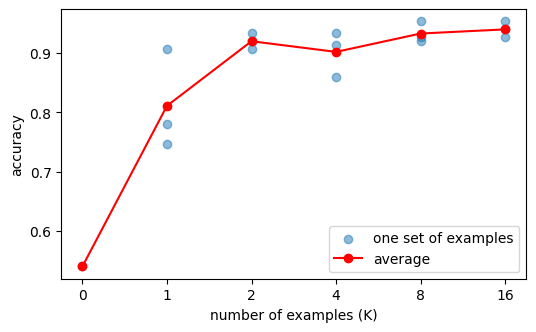

In [6]:
rows = []
for K in [0, 1, 2, 4, 8, 16]:
    for seed in ([0] if K == 0 else [1, 2, 3]):
        rows.append({"K": K, "seed": seed, "accuracy": accuracy(draw_demos(K, seed))})
count = pd.DataFrame(rows)

summary = count.groupby("K").accuracy.agg(["mean", "min", "max"]).round(3)
display(summary)

plt.figure(figsize=(6, 3.5))
plt.scatter(count.K.astype(str), count.accuracy, alpha=0.5, label="one set of examples")
plt.plot(summary.index.astype(str), summary["mean"], "r-o", label="average")
plt.xlabel("number of examples (K)"); plt.ylabel("accuracy"); plt.legend(); plt.show()

**What to look for:** does accuracy keep climbing as K grows, or does it flatten out? Where does most of the gain happen?

### 📋 Report · Experiment 1: how many examples?

K = 0, 1, 2, 4, 8, 16, with 3 different random sets of examples for each K (1 for K = 0).

| K | mean | min | max | spread between sets |
|---|---|---|---|---|
| 0 | 0.540 | 0.540 | 0.540 | n/a |
| 1 | 0.811 | 0.747 | 0.907 | **16.0 pp** |
| 2 | 0.920 | 0.907 | 0.933 | 2.6 pp |
| 4 | 0.902 | 0.860 | 0.933 | 7.3 pp |
| 8 | 0.933 | 0.920 | 0.953 | 3.3 pp |
| 16 | 0.940 | 0.927 | 0.953 | 2.6 pp |

**What it shows**
- **Most of the gain comes from the first two examples**: 0.54 → 0.81 → 0.92. After that the curve climbs slowly (0.90 → 0.93 → 0.94), and K = 4 is actually below K = 2, a dip that is within the spread between sets.
- **With one example, *which* example you pick matters enormously:** accuracy ranges from 0.747 to 0.907 across three sets. The notebook does not record why, but with a single example its label and wording can sway the model heavily.
- **The spread between sets shrinks** after K = 1 (about 3-7 points from K = 2 on), so more examples also make the result less dependent on luck.
- Even at K = 16 accuracy is 0.94, not 1.0: this is a real task with some hard sentences.


## 5. Experiment 2: does the order matter?

We take **one** set of 8 examples and shuffle it 6 different ways. The examples are identical. Only their order changes.

In [7]:
base = draw_demos(8, seed=1)
order_scores = []
for i in range(6):
    shuffled = base.copy()
    random.Random(i).shuffle(shuffled)
    order_scores.append(accuracy(shuffled))

print("accuracy for 6 orderings:", [round(a, 3) for a in order_scores])
print(f"best minus worst: {(max(order_scores) - min(order_scores)) * 100:.1f} percentage points")

accuracy for 6 orderings: [0.927, 0.953, 0.94, 0.933, 0.953, 0.953]
best minus worst: 2.7 percentage points


### 📋 Report · Experiment 2: does the order matter?

One set of 8 examples (seed 1), shuffled 6 ways:

`0.927, 0.953, 0.940, 0.933, 0.953, 0.953` → **best minus worst = 2.7 percentage points**.

**What it shows.** Reordering identical examples moves accuracy by up to about 2.7 points (three of the six orders give exactly the same 0.953). That is **well below the roughly 8-point noise band** the notebook defines, and about the same as the gap between different sets at K = 8 (3.3 points). So order has a small effect here.

**Caution.** This uses a *single* set of examples (seed 1). Other sets could behave differently, so a 2.7-point order effect has limited support.


## 6. Experiment 3: does the format matter?

Same 8 examples, written in four different styles (see `FORMATS` above). We repeat with 3 different sets of examples and average.

In [8]:
rows = []
for fmt in FORMATS:
    for seed in [1, 2, 3]:
        rows.append({"format": fmt, "seed": seed, "accuracy": accuracy(draw_demos(8, seed), fmt)})
fmt_df = pd.DataFrame(rows)

fmt_summary = fmt_df.groupby("format").accuracy.mean().sort_values(ascending=False).round(3)
display(fmt_summary)

,accuracy
format,
question/answer,0.942
text/label,0.940
arrow,0.938
review/sentiment,0.933


### 📋 Report · Experiment 3: does the format matter?

The same 8 examples (3 sets, averaged) written four ways:

| format | mean accuracy |
|---|---|
| question/answer | 0.942 |
| text/label | 0.940 |
| arrow | 0.938 |
| review/sentiment | 0.933 |

**What it shows.** The best and worst formats differ by **0.9 points**, far inside the noise. With 8 examples this model reads all four layouts about equally well.

**Consistency check:** `review/sentiment` at K = 8 averages **0.933** here, and the same configuration (same seeds, same default format) also gave 0.933 in Experiment 1 and as the 0-wrong row in Experiment 4. They agree, which is what should happen.


## 7. Experiment 4: what if the example labels are wrong?

We take sets of 8 examples and **flip the label** on some of them (a positive review marked negative, and the other way round). We try 0, 4 and 8 wrong labels.

In [9]:
def flip_labels(demos, n_wrong, seed):
    rng = random.Random(seed)
    to_flip = set(rng.sample(range(len(demos)), n_wrong))
    return [(s, 1 - label if i in to_flip else label) for i, (s, label) in enumerate(demos)]


rows = []
for n_wrong in [0, 4, 8]:
    for seed in [1, 2, 3]:
        demos = flip_labels(draw_demos(8, seed), n_wrong, seed)
        rows.append({"wrong labels (of 8)": n_wrong, "seed": seed, "accuracy": accuracy(demos)})
labels_df = pd.DataFrame(rows)

label_summary = labels_df.groupby("wrong labels (of 8)").accuracy.mean().round(3)
display(label_summary)

,accuracy
wrong labels (of 8),
0,0.933
4,0.889
8,0.560


### 📋 Report · Experiment 4: what if the example labels are wrong?

8 examples with 0, 4 or all 8 labels flipped (3 sets each):

| wrong labels (of 8) | mean accuracy |
|---|---|
| 0 | 0.933 |
| 4 | **0.889** (−4.4 pp) |
| 8 | **0.560** (−37.3 pp) |

**What it shows**
- **Half-wrong labels barely hurt** (a 4-point drop, roughly the size of the noise). The model is still mostly using what it already knows about sentiment.
- **All labels wrong hurts badly** (0.56): the examples consistently say "positive means bad", and that pulls the model a long way. But it only falls to about chance. If the model simply copied the example labels, accuracy would drop well *below* 50%, so it is not fully following the flipped rule; it still leans on what it already knows about sentiment.
- 0.56 is only about 1.5 standard errors above 50%, so do not read "still a little above chance" as a finding.


## 8. Putting it together

For each thing we changed, the **spread** is the best average accuracy minus the worst, in percentage points. A big spread means that factor matters.

**How big is "just noise"?** Our test set has only 150 sentences, so one accuracy number can be off by about 4 points by chance alone (the *standard error*). Changes smaller than about 8 points (two standard errors, the grey band) should not be trusted.

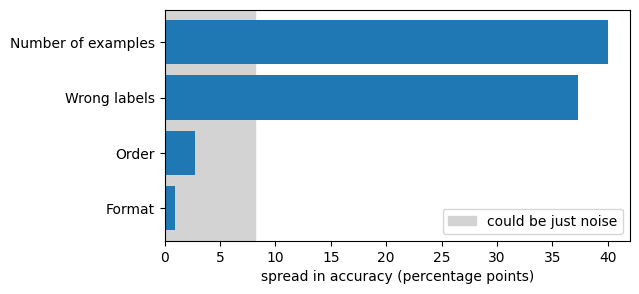

,spread (points)
Format,0.9
Order,2.7
Wrong labels,37.3
Number of examples,40.0


In [10]:
spread = {
    "Number of examples": summary["mean"].max() - summary["mean"].min(),
    "Wrong labels":       label_summary.max() - label_summary.min(),
    "Format":             fmt_summary.max() - fmt_summary.min(),
    "Order":              max(order_scores) - min(order_scores),
}
spread = pd.Series(spread).mul(100).round(1).sort_values()

noise = 2 * np.sqrt(0.25 / len(test)) * 100      # about 8 points
plt.figure(figsize=(6, 3))
plt.axvspan(0, noise, color="lightgrey", label="could be just noise")
plt.barh(spread.index, spread.values)
plt.xlabel("spread in accuracy (percentage points)"); plt.legend(); plt.show()

spread.to_frame("spread (points)")

In [11]:
# save every number so you can look at it later
allrows = pd.concat([
    count.assign(experiment="count"),
    fmt_df.assign(experiment="format"),
    labels_df.assign(experiment="wrong labels"),
])
allrows.to_csv("fewshot_results.csv", index=False)
print("saved fewshot_results.csv")

saved fewshot_results.csv


### 📋 Report · 8. Putting it together

| factor | spread (points) | how it was measured |
|---|---|---|
| Format | **0.9** | best minus worst format mean |
| Order | **2.7** | best minus worst of 6 orderings (one set) |
| Wrong labels | **37.3** | 0 wrong vs 8 wrong |
| Number of examples | **40.0** | K = 0 vs the best K |

The **grey band** is ±2 standard errors, about **8.2 points** (the standard error of one accuracy on 150 sentences is about 4.1).

**Reading it**
- **Two factors are far above the band:** number of examples (40.0) and wrong labels (37.3). **Order (2.7) and format (0.9) are inside it**, so treat them as not clearly different from zero.
- **The 40.0 is mostly "none vs some".** Almost all of it is the jump from K = 0 (0.54) to K = 2 (0.92). From K = 2 to K = 16 the means move about 3-4 points.
- **Wrong labels compares extremes:** "perfect" against "every label wrong". That is a deliberate sabotage, not a fair comparison with a mild change like reordering.
- **The band is conservative here.** It assumes accuracy near 50%. At about 93% accuracy the real standard error is nearer 2 points, so the band would be around 4 points. Order (2.7) and format (0.9) would still be inside it.

The cell also saved every result to `fewshot_results.csv` (37 runs: 16 for count, 12 for format, 9 for wrong labels).


## 9. Optional: temperature, top-k and top-p

These settings change how a model *picks* the next word when it writes text. We did not use them above, because they add randomness. Here we only look at what they do to the model's word probabilities for one prompt.

- **Temperature** (T): below 1 makes the model more certain, above 1 more random.
- **Top-k**: keep only the k most likely words.
- **Top-p**: keep the fewest top words whose probabilities add up to p.

*Entropy* measures how uncertain the model is (higher means more spread out).

In [12]:
text = "The best thing about learning a new language is"
inputs = tok(text, return_tensors="pt").to(device)
with torch.no_grad():
    logits = model(**inputs).logits[0, -1].float()


def show(T=1.0, top_k=None, top_p=None):
    probs = torch.softmax(logits / T, dim=0)
    sorted_p, sorted_ids = probs.sort(descending=True)
    keep = len(sorted_p)
    if top_k:
        keep = min(keep, top_k)
    if top_p:
        keep = min(keep, int((sorted_p.cumsum(0) < top_p).sum().item()) + 1)
    kept = sorted_p[:keep] / sorted_p[:keep].sum()
    entropy = -(kept * kept.clamp_min(1e-12).log2()).sum().item()
    best = ", ".join(f"{tok.decode(sorted_ids[j])!r} {kept[j].item():.2f}" for j in range(3))
    print(f"T={T}, top_k={top_k}, top_p={top_p}:  words kept = {keep:>6},  entropy = {entropy:5.2f} bits,  top 3: {best}")


show(T=1.0)
show(T=0.5)
show(T=2.0)
show(T=1.0, top_k=5)
show(T=1.0, top_p=0.9)
show(T=2.0, top_p=0.9)

T=1.0, top_k=None, top_p=None:  words kept = 151936,  entropy =  3.75 bits,  top 3: ' that' 0.49, ' the' 0.14, ' being' 0.04
T=0.5, top_k=None, top_p=None:  words kept = 151936,  entropy =  0.57 bits,  top 3: ' that' 0.91, ' the' 0.08, ' being' 0.01
T=2.0, top_k=None, top_p=None:  words kept = 151936,  entropy = 12.47 bits,  top 3: ' that' 0.04, ' the' 0.02, ' being' 0.01
T=1.0, top_k=5, top_p=None:  words kept =      5,  entropy =  1.38 bits,  top 3: ' that' 0.68, ' the' 0.20, ' being' 0.05
T=1.0, top_k=None, top_p=0.9:  words kept =     30,  entropy =  2.74 bits,  top 3: ' that' 0.54, ' the' 0.16, ' being' 0.04
T=2.0, top_k=None, top_p=0.9:  words kept =  23339,  entropy = 11.52 bits,  top 3: ' that' 0.04, ' the' 0.02, ' being' 0.01


### 📋 Report · 9. Temperature, top-k and top-p (optional)

For the prompt "The best thing about learning a new language is":

| setting | words kept | entropy (bits) | top word |
|---|---|---|---|
| T = 1 | 151,936 | 3.75 | ` that` 0.49 |
| T = 0.5 | 151,936 | 0.57 | ` that` 0.91 |
| T = 2 | 151,936 | 12.47 | ` that` 0.04 |
| T = 1, top-k = 5 | **5** | 1.38 | ` that` 0.68 |
| T = 1, top-p = 0.9 | **30** | 2.74 | ` that` 0.54 |
| T = 2, top-p = 0.9 | **23,339** | 11.52 | ` that` 0.04 |

**What it shows**
- **Temperature changes how spread out the probabilities are** (entropy 0.57 → 12.47 bits) **but never which word is first.**
- **Top-k keeps exactly k words**, always. **Top-p adapts:** 30 words at T = 1, but 23,339 at T = 2, because a flat distribution needs a huge set to reach 90%.
- This section is independent of the experiments above: nothing there uses these settings, because they only matter when *sampling* text, and the experiments score two words directly.


## What to write down

Fill these in yourself from the numbers above:

1. Which factor moved accuracy the most? Which barely mattered?
2. Did adding examples help? After how many did it stop helping?
3. Did wrong labels hurt more or less than you expected?
4. What would you change to make this test harder or more trustworthy? (A hint: look at how high the accuracy already is.)

### 📋 Report · The whole notebook in one page

**What was tested.** On real SST-2 sentiment data, with Qwen2.5-1.5B scored deterministically on 150 fixed sentences, how much accuracy changes with the number, order and format of few-shot examples, and with wrong example labels.

**What happened**
1. **Examples are essential:** 0.54 with none, 0.81 with one, 0.92 with two, and 0.94 by 16.
2. **Which example you pick matters most when there is only one:** 0.747 to 0.907 across three sets at K = 1. The spread between sets shrinks as K grows.
3. **Order (2.7 points) and format (0.9) barely mattered**, both inside the noise band.
4. **Wrong labels matter only when they are overwhelming:** half wrong cost 4 points; all wrong dropped accuracy to 0.56.

**Evidence for the four "What to write down" prompts** (the write-up is yours)
- *Which factor moved most / least:* number of examples (40.0) and wrong labels (37.3) vs format (0.9), order (2.7).
- *Did adding examples help, and when did it stop:* big gains to K = 2, small ones after.
- *Wrong labels:* 4 wrong cost 4.4 points, 8 wrong cost 37.3.
- *Harder or more trustworthy test:* accuracy is already 93-94% at K ≥ 8, so little room is left to detect small effects. More test sentences, more sets of examples per setting, or a smaller model would help.

**Caveats to watch**
- The "spread" for number of examples and wrong labels are extremes versus the middle; the others are small variations, so the ranking is not like for like.
- Only 3 sets per setting and **one set** for the order test, so a 2.7-point order effect has limited support.
- The notebook never records the share of positive guesses, so it cannot say *why* zero-shot is so weak. Adding it would show whether the model just leans to one label.

**Good follow-ups:** record the share of "positive" guesses; repeat the order test over several sets; flip labels at random (rather than with a fixed count) and keep the label mix balanced; rerun with the 0.5B model to see whether smaller models behave differently.
